# Giai đoạn 2 — Tiền xử lý dữ liệu

Đọc 14 CSV gốc, kiểm tra khóa, liên kết và kiểu dữ liệu, sau đó tạo hai bảng phân tích ở cấp đơn hàng và cấp dòng hàng. Nếu bản CSV đã có, notebook so từng dòng với kết quả tính lại.

Giai đoạn 2 bảo toàn 14 nguồn và tạo hai view dùng chung. Giữ bất thường đã được duyệt, phân biệt nguồn, diễn giải và điều chưa xác minh. Notebook thực thi code trong `src/preprocessing`, không chứa bản sao thuật toán nguồn. Không huấn luyện mô hình, tính RFM, scaling hoặc lag/rolling.

Kết quả bên dưới được tính thực tế trong kernel sạch. Tiền kiểm chứng dùng Decimal; biểu đồ có thể chuyển float chỉ để hiển thị.

In [1]:
from pathlib import Path
import os,sys,json
sys.dont_write_bytecode=True
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from datathon.preprocessing.common import CommonPreprocessing
from datathon.preprocessing.delivery import validate_orders,validate_items,validate_financials,validate_supporting,publish,json_safe
from datathon.preprocessing.foundation import exact_sum
%matplotlib inline
pd.set_option('display.max_rows',16)
pd.set_option('display.max_columns',9)
pd.set_option('display.max_colwidth',70)
plt.rcParams.update({'figure.figsize':(10,4),'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
print('PROJECT_ROOT:',ROOT)
print('Python:',sys.version.split()[0],'Pandas:',pd.__version__)
run=CommonPreprocessing(ROOT,chunk_size=25000)

PROJECT_ROOT: E:\SGU\Ky1_4\DA\Datathon_2026_RetailAnalytics
Python: 3.11.7 Pandas: 2.2.3


## 1. Tổng quan và đọc 14 bảng

Đọc theo lô, tách nguyên văn và kiểu làm việc, kiểm tra header, khóa xuyên lô và FK trước JOIN. SQLite chỉ là vùng làm việc tạm; tiền lưu chuỗi Decimal. Hash được đối chiếu trước khi công bố. Không xuất bản sao 14 nguồn.

In [2]:
run.load(progress=lambda name,n:print(f'{name}: {n:,} bản ghi'))
overview=pd.DataFrame([{'Bảng':n,'Dòng nguồn':s['rows'],'Cột nguồn':len(s['columns']),'SHA-256':s['sha256']} for n,s in run.sources.items()])
display(overview)

customers: 121,930 bản ghi


geography: 39,948 bản ghi


orders: 646,945 bản ghi


order_items: 714,669 bản ghi


payments: 646,945 bản ghi


products: 2,412 bản ghi
promotions: 50 bản ghi


... (3 outputs left out)

inventory: 60,247 bản ghi


web_traffic: 3,652 bản ghi
sales: 3,833 bản ghi


sample_submission: 548 bản ghi


,Bảng,Dòng nguồn,Cột nguồn,SHA-256
0,customers,121930,7,a6fa47944039de6712dc865027e2e4e4e08c920f84a8b5c162335cc8d7220a56
1,geography,39948,4,f5d150bdfdfca7ac0c38118b1f5f8ea1b3f5de4cd23fa700d5aa0adcd2ab6353
2,orders,646945,8,f4b3029f386f5f5a6baabd78aad0140e5a101ea6975f4cbaba04976813f3f3af
3,order_items,714669,7,a8b2adfe54eec0dda79ced28e5987d6846b7f31cb6052356ab3a1772cc85e0bc
4,payments,646945,4,aacef7716fe1c1442bc46e8885019cf1d67e12655c2e0f28bd0c9e92e145a6e7
5,products,2412,8,6a9d322d1c5ebacb474932a08a60eedd5338acbcfdda577085bae1aa1a4a3d4f
6,promotions,50,10,158ee5843ee41a28b5f5748ab2c73bd712524da6c00930fa9e80774e3751b0be
7,returns,39939,7,501717bc76cf237c0dbbb68f586351870047198042c4232376983fec94699534
8,shipments,566067,4,9a96bd80dde30dae22d726cdcd414dd8463b879de4ec1f09334c22396a56242b
9,reviews,113551,7,5230859408955d611bc430df5d788eb66fedd56f3be9f6fe912af6da643fa0f1


## 2. Hai mươi bốn chính sách đã duyệt

G = giữ nguyên; C = cờ; K = kiểm chứng; V = view; B = parse/tính trường dẫn xuất. Các mốc số đếm gắn với hash snapshot, không phải ràng buộc bất biến cho dataset khác.

In [3]:
contract=reference_path('preprocessing_policies.md').read_text()
import re
policy=[line for line in contract.splitlines() if re.match(r'\| (0[1-9]|1[0-9]|2[0-4]) \|',line)]
assert len(policy)==24
display(Markdown('| DQ | Chính sách | Kiểm chứng | Phạm vi |\n|---|---|---|---|\n'+'\n'.join(policy)))

| DQ | Chính sách | Kiểm chứng | Phạm vi |
|---|---|---|---|
| 01 | Giữ 477.453 đơn trước đăng ký; không sửa ngày/loại đơn | V01.parse_date/analyze; G+C+K; cờ order_before_signup_flag tính trực tiếp, thiếu căn cứ là NA | Parse nền ở 2.3.1.3; cờ đủ từng đơn ở 2.3.2 |
| 02 | Parse đúng định dạng từng cột, giữ ngày thực tế | V01.parse_date, V06.strict_dates; G+B+K; kiểm tra cú pháp/lịch/ngày nhuận, raw bất biến | Nền tảng |
| 03 | Không dùng parser signup ISO sai của Thu Luyn | Dùng parser V01 đúng định dạng, không sửa nguồn | Nền tảng không dùng parser sai; không sửa notebook trong bước này |
| 04 | Giữ NULL và hai vị trí mã trên dòng hàng | V06.null_kind; G+K; raw/states giữ dấu vết, không điền mã | Nền tảng |
| 05 | Giữ cả sáu trạng thái trong dữ liệu chung | V02.analyze ở bước view; G+K; không lọc khi đọc, bảo toàn tập trạng thái | Đọc nền; view đơn ở 2.3.2; lọc riêng theo bài toán |
| 06 | Phân biệt Gross, Discount, Net, Payment, sales.Revenue; Revenue đối chứng Gross trước giảm trên mọi trạng thái; Revenue−COGS chưa là lợi nhuận thực | V02.analyze/compare/independent_audit; G+B+V+K; Discount một lần/dòng, tổng hợp con trước JOIN | Decimal nền; đối soát/view ở 2.3.2/2.3.3 |
| 07 | Giữ products.cogs và sales.COGS, không tạo giá vốn lịch sử/ép bằng nhau | V02.decimal_value/compare; G+B+K; COGS nguồn và đối chứng riêng, không làm tròn cent | Decimal nền; đối chứng sau |
| 08 | Giữ cả 714.669 items, gồm cặp lặp; ID ổn định truy nguyên | G+B+K; source_row_id trước sort/JOIN; mỗi bản ghi nguồn một ID | ID nền; order_items_common ở 2.3.3 |
| 09 | Giữ 39.939 returns/return_id, kể cả cặp lặp | V03.analyze/independent_audit; G+V+K; tổng hợp đúng cấp trước nối | Khóa/FK nền; tổng hợp sau |
| 10 | Giữ đơn thiếu shipment, LEFT JOIN, gắn cờ; không tạo ngày | NV03.build_shipping_views/build_cross034; G+C+V; một dòng đơn sau nối | Nền chỉ đọc; orders_common ở 2.3.2 |
| 11 | Status returned và có returns là hai thông tin riêng | V03.analyze; G+C+K; bảng chéo đủ bốn nhóm, không suy nhóm thiếu từ chênh tổng | Khóa/FK nền; bảng chéo/cờ ở 2.3.2 |
| 12 | Giữ refund vượt payment, không cap/xóa/sửa | V03.analyze/financial_difference; G+C+K; tổng hợp riêng từng bảng theo đơn, hai phép so độc lập | Decimal nền; đối soát ở 2.3.2 |
| 13 | Giữ inventory.units_sold khác tổng quantity | V04.analyze/compare_measure; G+V+K; không sửa hai lượng để ép khớp | Kiểu/FK nền; đối soát ở bước sau/Bài toán 1 |
| 14 | Không fill 0/ffill/bfill hoặc tạo snapshot cho cặp thiếu | V04/NV05 coverage; G+K; báo giao/hợp và ngoài phạm vi, không sinh tồn kho | Nền giữ mọi dòng; báo coverage sau |
| 15 | Residual chỉ giữa tháng liên tiếp, residual=0 chưa chứng minh kiểm kê, không cộng hàng trả vào received | NV05.adjacent54; G+B+K; khoảng tháng thiếu không bắc cầu | Bước kiểm chứng sau/Bài toán 1 |
| 16 | Giữ reorder_flag=0 ở 60.247 dòng; biến hằng, không nhãn giả | V05.analyze/assess; G+K; mốc theo snapshot, không cấm giá trị khác ở mọi dataset | Nền parse giữ giá trị; hồ sơ biến sau |
| 17 | Giữ hai mã; Discount một lần/dòng; lượt mã không phân bổ tiền | V06.analyze, logic NV06; G+V+K; view slot khóa (item_row_id, slot) tách khỏi view tiền | Giữ slot nền; view nếu cần sau 2.3.3 |
| 18 | Giữ chương trình/mã/Discount; chỉ ứng viên dưới ngưỡng Gross/Net | NV06 cell code 43; C+K; so tổng đơn, không gọi vi phạm/loại mã | Chưa xây ở nền; bước phân tích/view sau |
| 19 | Giữ bounce theo thang nguồn; ba loại kênh khác cấp, không attribution bằng tên | V07/V08.analyze; G+K; không đổi thang hoặc tạo FK kênh | Nền giữ kiểu/nhãn; kiểm chứng/chỉ tiêu sau |
| 20 | Giữ khoảng quan sát từng bảng; phân biệt thiếu/trong/ngoài phủ, không suy sau cuối kỳ | V04/V07/V08/V09; G+C+K; không sinh dòng/ngày/0 | Nền không fill; báo coverage ở bước sau |
| 21 | RFM delivered 04/07/2012–31/12/2022, chốt 31/12/2022; R từ đơn delivered gần nhất, F distinct order_id, M tổng quantity×unit_price−discount; không cộng Payment/trừ Refund; giữ 36.815 khách ngoài tập với R không xác định | NV02.build_behavior_scope/build_value_orders; V+B+K; chưa chuẩn hóa/phân cụm | Bài toán 2; nền không tính RFM |
| 22 | Giữ Date/Revenue/COGS của 3.833 ngày Sales; 548 ngày template chỉ lịch/schema, không nhãn; chưa lag/rolling/scaling/model | V09.analyze/inspect_roundtrip; G+V+K; không trộn template vào lịch sử | Nền đọc hai bảng riêng; chuẩn bị mô hình thuộc Bài toán 3 |
| 23 | Giữ baseline gốc; không kế thừa lỗi TEST_FILE/đường dẫn/đánh giá leakage | G+K; hash baseline, không thực thi từ nền | Backtest Bài toán 3 |
| 24 | Không sửa nguồn để test đạt; quản lý manifest/dependency/root/integrity, công bố sau kiểm chứng | digest, V02.require_key/require_link, notebook_integrity; K; nguồn và file nghiệm thu bất biến | Root/hash/ID nền; vấn đề repo còn lại báo riêng, không tự sửa |

## 3. Xây dựng orders_common

Orders là tập đơn gốc, giữ nguyên tám cột và mọi trạng thái. Items nối Products theo many-to-one để lấy COGS tham chiếu; Items, Payments, Returns, Shipments được tổng hợp độc lập rồi LEFT JOIN một-một. Không nhân tiền theo số bản ghi con.

Không có Returns khác Refund bằng 0: tiền và cờ so sánh không đủ căn cứ được giữ NA. DQ-11 dùng bảng chéo đầy đủ, không suy từ chênh hai tổng.

In [4]:
orders=run.build_orders_common()
orders_report=validate_orders(run)
display(orders.head(6)[['order_id','order_status','item_rows','gross_amount','net_amount','payment_amount','refund_amount_observed','cogs_check_amount']])
display(pd.DataFrame(orders_report['dq11_cross']))
display(pd.DataFrame(orders_report['flags']).T.rename(columns={'true':'True','false':'False','unknown':'NA'}))
print('Schema:',len(orders.schema),'cột; số đơn:',len(orders),'đủ điều kiện:',orders_report['accepted'])

,order_id,order_status,item_rows,gross_amount,net_amount,payment_amount,refund_amount_observed,cogs_check_amount
0,1,delivered,1,7967.54,7967.54,7967.54,None,7376.586058659216
1,2,returned,1,71163.75,71163.75,71163.75,52458.01,62913.929616483218
2,3,delivered,1,33660.99,33660.99,33660.99,None,30273.03676696092
3,4,delivered,1,53196.25,53196.25,53196.25,None,46027.152389705880
4,6,delivered,1,1597.84,1597.84,1597.84,None,1048.696357245283
5,7,delivered,1,9800.94,9800.94,9800.94,None,8027.0187860377356


,returned,has_return_record,orders
0,True,True,36062
1,True,False,80
2,False,True,0
3,False,False,610803


,True,False,NA
order_before_signup_flag,477453,169492,0
items_repeated_pair_flag,16,646929,0
multiple_return_records_flag,3801,643144,0
delivered_missing_shipment_flag,524,646421,0
returned_missing_return_detail_flag,80,646865,0
refund_gt_payment_flag,3640,32422,610883
refund_gt_payment_over_tolerance_flag,3640,32422,610883


Schema: 30 cột; số đơn: 646945 đủ điều kiện: True


## 4. JOIN, trạng thái và những bất thường được giữ

Các nhóm cờ có thể giao nhau, không cộng số đếm thành tổng lỗi. Returned thiếu Returns, delivered thiếu shipment, items lặp cặp và refund vượt payment đều giữ nguyên.

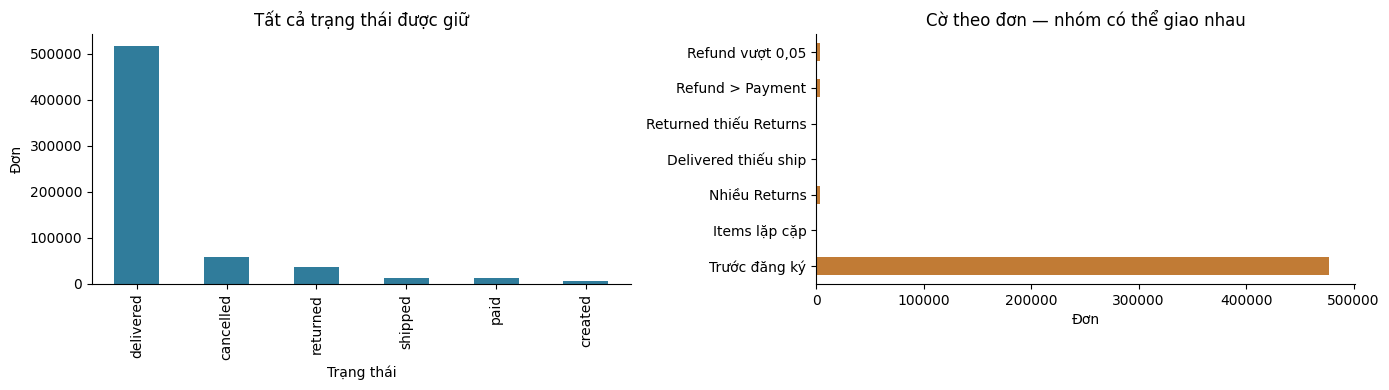

,check,status
0,FK:customers:zip->geography,passed
1,FK:orders:customer_id->customers,passed
2,FK:orders:zip->geography,passed
3,FK:order_items:order_id->orders,passed
4,FK:order_items:product_id->products,passed
...,...,...
25,orders:count:shipment_rows,passed
26,orders:DQ11_partition,passed
27,orders:missing_child:gross_amount,passed
28,orders:missing_child:payment_amount,passed


In [5]:
status=pd.Series(orders_report['status_distribution']).sort_values(ascending=False)
flags=pd.Series({k:v['true'] for k,v in orders_report['flags'].items()})
fig,axes=plt.subplots(1,2,figsize=(14,4))
status.plot.bar(ax=axes[0],color='#307c9b');axes[0].set(title='Tất cả trạng thái được giữ',ylabel='Đơn',xlabel='Trạng thái')
flags.index=['Trước đăng ký','Items lặp cặp','Nhiều Returns','Delivered thiếu ship','Returned thiếu Returns','Refund > Payment','Refund vượt 0,05']
flags.plot.barh(ax=axes[1],color='#c17b35');axes[1].set(title='Cờ theo đơn — nhóm có thể giao nhau',xlabel='Đơn')
plt.tight_layout();plt.show()
display(pd.DataFrame([c for c in run.checks if c['check'].startswith(('FK:','orders:'))])[['check','status']])

## 5. Xây dựng order_items_common và bảo toàn tiền

Một dòng cho mỗi bản ghi nguồn, kể cả trùng cặp. Giữ hai slot promo; Discount chỉ tính một lần. COGS là tham chiếu từ Products. Payment/Refund cấp đơn không được chép thành chỉ tiêu cộng trên dòng.

In [6]:
items=run.build_order_items_common()
items_report=validate_items(run)
financial=validate_financials(run)
display(items.head(6)[['item_row_id','order_id','quantity','promo_id','promo_id_2','line_gross','line_discount','line_net','line_cogs_check']])
display(pd.DataFrame([{'Chỉ tiêu':k,'Tổng nguồn độc lập (Decimal)':str(v)} for k,v in financial['source_totals'].items()]))
print('Dòng hàng:',len(items),'cột:',len(items.schema),'đủ điều kiện:',items_report['accepted'])
print('Oracle: CSV/Decimal trực tiếp; không dùng COGS JSON đã qua float làm chuẩn tuyệt đối.')

,item_row_id,order_id,quantity,promo_id,promo_id_2,line_gross,line_discount,line_net,line_cogs_check
0,171312783c5f55b9260d11a2a3a2592275a0bde4ed8982cf7fc4f82e63d8171c,1,7,<NA>,<NA>,7967.54,0.0,7967.54,7376.586058659216
1,ad5cad666ee4005bb44b163ebb93ac8bc6099b5badc65ab38ca9e29b05ef496b,2,7,<NA>,<NA>,71163.75,0.0,71163.75,62913.929616483218
2,f6fe15da457b8205df4be4b3c578639ad522d1f3160d7032a01fcdfe65160b6a,3,3,<NA>,<NA>,33660.99,0.0,33660.99,30273.03676696092
3,39fdf26e616aa43bb6473ec4ac49307a80f8fa4398fadfc8df18281c00e1439f,4,5,<NA>,<NA>,53196.25,0.0,53196.25,46027.152389705880
4,cf7fa089a860b40e56776b9b5baa5a508145730afccd148d4b263fbbc0ed887b,6,1,<NA>,<NA>,1597.84,0.0,1597.84,1048.696357245283
5,b96c03d85f7d16dad20f45800293edca5cd1857a590ae006ca55173b7c77e2a8,7,6,<NA>,<NA>,9800.94,0.0,9800.94,8027.0187860377356


,Chỉ tiêu,Tổng nguồn độc lập (Decimal)
0,quantity,3213143
1,gross,16430476585.53
2,discount,749607320.10
3,net,15680869265.43
4,payment,15680869265.43
5,refund,510598506.55
6,returned_quantity,109586
7,cogs,14163450519.14700961898794


Dòng hàng: 714669 cột: 19 đủ điều kiện: True
Oracle: CSV/Decimal trực tiếp; không dùng COGS JSON đã qua float làm chuẩn tuyệt đối.


## 6. Kiểm chứng nguồn bổ trợ

Báo cáo GD1 chỉ được kế thừa khi mọi hash đầu vào khớp và kiểm tra kỹ thuật đã đạt. Findings vẫn giữ nguyên, không đồng nhất với lỗi pipeline. V09 được tính lại trên Sales/template. Inventory không lấp snapshot hay ép units_sold khớp giao dịch; residual chỉ xét tháng liền nhau và chưa xác nhận kiểm kê thực tế.

RFM chỉ xác nhận phạm vi; chưa tính R/F/M. Dữ liệu dự báo bàn giao lịch sử Sales và lịch tương lai, không coi giá trị template là nhãn.

In [7]:
support=validate_supporting(run)
display(pd.DataFrame([{'Kiểm chứng':k,**{a:v[a] for a in ['status','source_hashes_match','technical_checks_passed'] if a in v}} for k,v in support['inherited_validations'].items()]))
display(pd.DataFrame([support['rfm_scope']]))
display(pd.DataFrame([support['inventory_residual']]))
display(pd.DataFrame([{'Nguồn lịch sử':support['forecast_handoff']['history_source'],'Ngày tương lai':len(support['forecast_handoff']['calendar']),'Bắt đầu':support['forecast_handoff']['calendar'][0],'Kết thúc':support['forecast_handoff']['calendar'][-1],'Giá trị mẫu là nhãn':support['forecast_handoff']['template_values_are_labels']}]))

,Kiểm chứng,status,source_hashes_match,technical_checks_passed
0,v01,reused_current_sources,True,True
1,v02,reused_current_sources,True,True
2,v03,reused_current_sources,True,True
3,v04,reused_current_sources,True,True
4,v05,reused_current_sources,True,True
5,v06,reused_current_sources,True,True
6,v07,reused_current_sources,True,True
7,v08,reused_current_sources,True,True
8,v09,reused_current_sources,True,True


,customers,eligible,outside,no_order_records,orders_but_no_eligible_delivered,reference_date,computed_rfm,recency_outside
0,121930,85115,36815,31684,5131,2022-12-31,False,None


,eligible_consecutive_pairs,zero_residual_pairs,physical_stock_verified,imputation
0,51524,51524,False,False


,Nguồn lịch sử,Ngày tương lai,Bắt đầu,Kết thúc,Giá trị mẫu là nhãn
0,data/raw/sales.csv,548,2023-01-01,2024-07-01,False


## 7. Minh họa dữ liệu bàn giao dự báo

Hai chỉ tiêu lịch sử giữ nguyên nguồn. Chuyển float dưới đây chỉ phục vụ biểu đồ; đối soát/xuất dữ liệu vẫn dùng Decimal. Không xây đặc trưng hoặc chia tập chung cho ba bài toán.

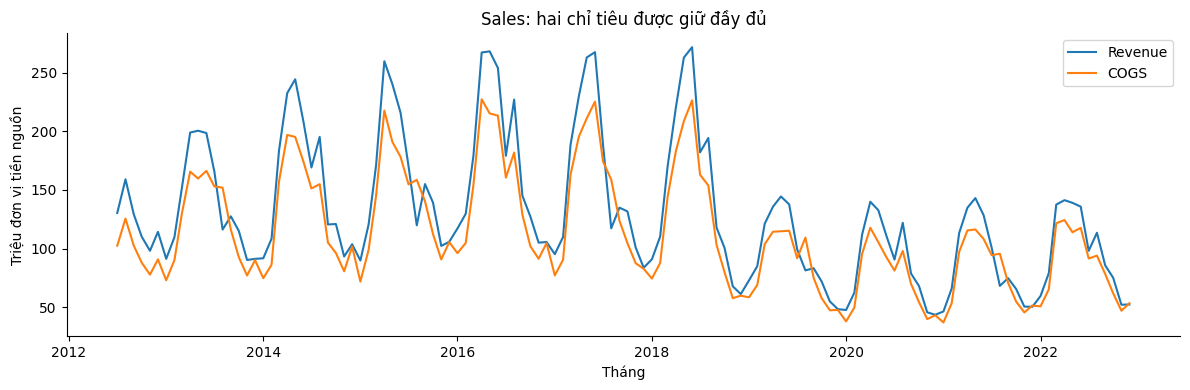

In [8]:
from decimal import Decimal
sales=pd.read_sql_query('SELECT _p_Date AS Date,_p_Revenue AS Revenue,_p_COGS AS COGS FROM sales ORDER BY _p_Date',run.connection)
sales['Date']=pd.to_datetime(sales.Date)
for col in ['Revenue','COGS']:sales[col]=sales[col].map(Decimal)
monthly=sales.groupby(sales.Date.dt.to_period('M'))[['Revenue','COGS']].agg(lambda x:exact_sum(x))
fig,ax=plt.subplots(figsize=(12,4))
for col in ['Revenue','COGS']:ax.plot(monthly.index.to_timestamp(),monthly[col].map(float)/1000000,label=col)
ax.set(title='Sales: hai chỉ tiêu được giữ đầy đủ',ylabel='Triệu đơn vị tiền nguồn',xlabel='Tháng');ax.legend();plt.tight_layout();plt.show()

## 8. Tổng hợp trước/sau và truy nguyên

Nguồn không bị thay đổi. Hai view là lớp bổ sung; số đơn/dòng và mọi khoản tiền phải bảo toàn. Cùng file/hash/thứ tự bản ghi CSV cho cùng ID nguồn; xuống dòng trong ô không tạo thêm bản ghi.

In [9]:
display(pd.DataFrame([{'Đầu vào':n,'Dòng nguồn':s['rows'],'Xử lý':'Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK'} for n,s in run.sources.items()]))
display(pd.DataFrame([{'View':'orders_common','Dòng đầu vào':run.sources['orders']['rows'],'Dòng đầu ra':len(orders),'Cột':len(orders.schema)}, {'View':'order_items_common','Dòng đầu vào':run.sources['order_items']['rows'],'Dòng đầu ra':len(items),'Cột':len(items.schema)}]))
example=orders.head(1).iloc[0].order_id
display(pd.DataFrame(run.lineage_for_order(example)))
print('Snapshot đã kiểm chứng:',run.report['snapshot_verified'])

,Đầu vào,Dòng nguồn,Xử lý
0,customers,121930,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
1,geography,39948,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
2,orders,646945,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
3,order_items,714669,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
4,payments,646945,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
5,products,2412,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
6,promotions,50,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
7,returns,39939,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
8,shipments,566067,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK
9,reviews,113551,Giữ nguyên nguồn; kiểm tra schema/kiểu/khóa/FK


,View,Dòng đầu vào,Dòng đầu ra,Cột
0,orders_common,646945,646945,30
1,order_items_common,714669,714669,19


,table,source_record_index,source_row_id,source_sha256
0,orders,1,e2be154ed39d9ac9190a78e74ae97d8ace45dbaf4dbd69ba945441fceded61e1,f4b3029f386f5f5a6baabd78aad0140e5a101ea6975f4cbaba04976813f3f3af
1,order_items,1,171312783c5f55b9260d11a2a3a2592275a0bde4ed8982cf7fc4f82e63d8171c,a8b2adfe54eec0dda79ced28e5987d6846b7f31cb6052356ab3a1772cc85e0bc
2,payments,1,b280e5c6258946777acbd620bede9cbe0e7be12f906983fcc0afd13c1d934006,aacef7716fe1c1442bc46e8885019cf1d67e12655c2e0f28bd0c9e92e145a6e7
3,shipments,1,67c6b638ea815be3b580ff78f9ea8d43d222384b81a8c0954c5ef632c2d1f85e,9a96bd80dde30dae22d726cdcd414dd8463b879de4ec1f09334c22396a56242b
4,customers,45430,5c4ddaa3255d3d477d0ef9c27a3608a952bbc4980a102f831a4205e7fed03463,a6fa47944039de6712dc865027e2e4e4e08c920f84a8b5c162335cc8d7220a56
5,products,1653,adb8ff5ab817de21d8834ef9b655325dd4a1b90a760ba5225ea7d6a9db4fd0e9,6a9d322d1c5ebacb474932a08a60eedd5338acbcfdda577085bae1aa1a4a3d4f


Snapshot đã kiểm chứng: True


## 9. Công bố sau nghiệm thu và bàn giao

Chỉ công bố nếu từng view đạt, có oracle độc lập và kiểm chứng bổ trợ. CSV dùng token `\N` cho NA; đọc lại bằng `read_processed()` với schema manifest, không để pandas suy ID/ZIP hoặc float. Round-trip so chính xác từng dòng với view. File đã tồn tại chỉ được xác minh nếu cùng manifest; không ghi đè âm thầm.

In [10]:
delivery=publish(run)
print('Trạng thái:',delivery['status'])
display(pd.DataFrame([{'View':n,'Dòng round-trip':e['rows'],'So từng dòng chính xác':e['exact_row_comparison'],'SHA-256 CSV':e['sha256']} for n,e in delivery['outputs'].items()]))
print('Manifest:',delivery['manifest'])
display(pd.DataFrame([{'Phép kiểm chứng': c['check'], 'Trạng thái': c['status']} for c in run.checks]))

Trạng thái: verified_existing


,View,Dòng round-trip,So từng dòng chính xác,SHA-256 CSV
0,orders_common,646945,True,3a3cadcb8114df20958a6721c38416b3f70d45182b1f57ba387b5a7d49e9b658
1,order_items_common,714669,True,4fa264c96bda7a2b59b14d1f3ec6416b1f9584c197fc3407298ffe242982f97c


Manifest: E:/SGU/Ky1_4/DA/Datathon_2026_RetailAnalytics/data/processed/preprocessing_manifest.json
Báo cáo: E:\SGU\Ky1_4\DA\Datathon_2026_RetailAnalytics\reports\tables\gd2\preprocessing_validation.json


## 10. Kết luận và giới hạn

- Bài toán 1: orders_common và order_items_common; mọi trạng thái và bất thường vẫn giữ, cờ không phải kết luận vi phạm nghiệp vụ.
- Bài toán 2: lọc delivered theo hợp đồng riêng, chốt 31/12/2022; giữ khách ngoài phạm vi và lý do. Chưa scaling/clustering.
- Bài toán 3: dùng Sales Date/Revenue/COGS, lịch/schema tương lai trong manifest. Không lấy giá trị mẫu làm nhãn. Status/Refund/Shipment trong view là snapshot cuối kỳ, không mặc định sẵn có tại mỗi fold lịch sử.
- Chưa xác minh tiền tệ/thuế/phí, giá vốn lịch sử, nghĩa NULL danh mục, stacking/eligibility, cấp kho và attribution marketing. Không suy lợi nhuận thực tế từ Revenue−COGS.
- Không sửa raw, baseline hoặc notebook lịch sử. Các kiểm thử chạy và trạng thái Git được lưu/báo riêng; không tự commit/push.

In [11]:
run.check_sources()
print('Số kiểm tra thực tế:',len(run.checks))
print('Không có kiểm tra unsafe:',all(c['status']=='passed' for c in run.checks))
print('Không có RFM/model/scaling/lag/rolling được thực hiện.')
run.close()

Số kiểm tra thực tế: 266
Không có kiểm tra unsafe: True
Không có RFM/model/scaling/lag/rolling được thực hiện.
